# AI-enabled Children Story Telling Market Research



In [1]:
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '..')

import tinytroupe
from tinytroupe import config_manager
from tinytroupe.agent import TinyPerson
from tinytroupe.environment import TinyWorld
from tinytroupe.factory import TinyPersonFactory
from tinytroupe.validation import TinyPersonValidator
from tinytroupe import control

from tinytroupe.extraction import ResultsExtractor
from tinytroupe.profiling import Profiler

from tinytroupe.validation import SimulationExperimentEmpiricalValidator, SimulationExperimentDataset, validate_simulation_experiment_empirically


!!!!
DISCLAIMER: TinyTroupe relies on Artificial Intelligence (AI) models to generate content. 
The AI models are not perfect and may produce inappropriate or inacurate results. 
For any serious or consequential use, please review the generated content before using it.
!!!!

Looking for default config on: c:\Users\pdasilva\repos\TinyTroupe\examples\..\tinytroupe\utils\..\config.ini
Found custom config on: c:\Users\pdasilva\repos\TinyTroupe\examples\config.ini
TinyTroupe version: 0.6.0
Current date and time (local): 2025-09-19 22:47:33
Current date and time (UTC):   2025-09-20 01:47:33

Current TinyTroupe configuration 
[OpenAI]
api_type = openai
azure_api_version = 2024-08-01-preview
model = gpt-5-mini
reasoning_model = o3-mini
embedding_model = text-embedding-3-small
max_completion_tokens = 32000
timeout = 480
max_attempts = 5
waiting_time = 0
exponential_backoff_factor = 5
reasoning_effort = high
cache_api_calls = False
cache_file_name = openai_api_cache.pickle
max_content_display_l

2025-09-19 22:48:03,212 - tinytroupe - DEBUG - Initializing OpenAIClient
2025-09-19 22:48:03,214 - tinytroupe - DEBUG - Initializing AzureClient
2025-09-19 22:48:03,216 - tinytroupe - DEBUG - Initializing OpenAIClient
2025-09-19 22:48:03,219 - tinytroupe - DEBUG - Initializing OllamaClient
2025-09-19 22:48:03,222 - tinytroupe - DEBUG - base_url set to None


In [2]:
config_manager.update("action_generator_enable_quality_checks", True)
config_manager.update("action_generator_quality_threshold", 6)

First of all, we'll use a cached simulation, to avoid having to recompute expensive steps unless really necessary. We accomplish this via the `control.begin()` function. The file it takes as an argument is the cache file that will be created and then updated as needed.

**Tip:** the ".cache." naming convention is used to indicate that the file is a cache file and will not be committed to the repository.

In [3]:
control.begin("ai_enabled_children_story_telling.cache.json")

2025-09-19 22:48:04,712 - tinytroupe - DEBUG - Starting simulation, cache_path=ai_enabled_children_story_telling.cache.json, auto_checkpoint=False.


## Prepare the survey and auxiliary elements

Main target nationality and population size.

In [4]:
target_nationality = "American"
population_size = 50

additional_demographic_specification = f"""
 ALL sampled people MUST have the following characteristics too:
   - Like reading books.
   - Parent with children aged 4 to 5 years old.
"""
  

Should we also compute the other nationalities? This might take a while, so we leave it as an option.

In [5]:
compute_other_nationalities = True

Descriptions and standard questions for the survey.

In [6]:
interviewer_introduction =\
    """
   Artificial Intelligence (AI) can now create compelling stories for young children, tell them aloud and 
   even generate illustrations of the scenes, like a regular book. We are considering creating a "digital story-teller" to leverage 
   this, and would like the opinion of parents. The key idea is that that the child would be able to independently talk to the AI 
   story-teller and request specific stories, anything the child can imagine. Our main doubt is HOW to deliver this technology to 
   the children.
   
   Your task is to order the options based on your preferences. The first option is the one you like the most, and the last option 
   is the one you like the least. So, for example, if you respond with "B, A, C, D, E", it means you prefer option B the most and 
   option E the least.
    """

interviewer_main_question =\
    """ 
    So the main question for you to rank the options is this: what kind of AI-enabled story-telling device would you buy for your very young children (3 to 5 y.o.)? 
    
    Pick from the options below (A, B, C, D, E) and please explain your choices. Here are the details about each option:


     - (A) DEDICATED SINGLE-PURPOSE DEVICE (AUDIO + IMAGES): A single-purpose portable device, where there are no apps or anything else. There is just a single button to turn it ON or OFF, plus a screen, and when ON the child can talk to an animated story-teller, ask stories and the device then tells the requested stories aloud, including related story illustrations too shown on a screen, all on demand. The child can interrupt it at any time too. There is nothing else, no other apps, no other info, nothing, it is just a story-teller device. The stories are told aloud and include static images (like a book, but on the screen). No parent supervision needed.
           PRICE:  Would cost the same as a regular low-end smartphone or tablet.

     - (B) NOTHING: I would rather NOT use ANY AI-enabled device or app for story-telling to my children.

     - (C) APP FOR YOUR EXISTING PHONE OR TABLET (AUDIO + IMAGES): An app for your existing smartphone or tablet, which the child can open any time, and then interact by voice with an animated storyteller. The child can talk to the app, ask for stories and then the stories are told aloud and include related story illustrations (like a book, but on the screen). The child can interrupt it at any time too. No parent supervision needed while using the app.
           PRICE: Would cost the same as any cheap app (US$ 10).

     - (D) DEDICATED SINGLE-PURPOSE DEVICE (AUDIO-ONLY): A single-purpose portable device, where there are no apps or anything else. There is just a single button to turn it ON or OFF, no screens, and when ON the child can talk to it, ask stories and the device then tells the requested stories aloud (no images) on demand. The child can interrupt it at any time too. There is nothing else, no other apps, no other info, nothing,  it is just a story-teller device. The stories are told aloud and have no images or videos - there's just a soft LED light to indicate whether the device is ON or OFF. No parent supervision needed
           PRICE:  Would cost the same as a regular low-end smartphone or tablet.

     - (E) APP FOR YOUR EXISTING PHONE OR TABLET (AUDIO-ONLY): An app for your existing smartphone or tablet, which the child can open any time, and then interact by voice. The child can talk to the app, ask for stories and then the stories would be told aloud on demand, no images nor videos though. The child can interrupt it at any time too. No parent supervision needed while using the app.
           PRICE: Would cost the same as any cheap app (US$ 10).

   IMPORTANT: Please respond with a list of single letter options (A, B, C, D, E), ordered according to your preferences. After that, you can 
   justify your choice. For example:
  
      "Ranking: B, D, C, A, E. Justification: ..."
   """

inner_monologue =\
    """
    I will be honest as I understand they are not here to judge me, but just to learn from me. 
    Such choices depend on many factors, but I will make my best guess, considering my current 
    situation in life, location, job and interests.

    Now I **must** first THINK deeply about the question, consider all the factors that might influence my decision,
    and only then I will TALK with my response to the question as best, as detailed and as honestly as I can.

    I will respect the expected response format, giving first my ranked choices and then justifying that ranking. I MUST adhere to the format strictly,
    saying "Ranking: ..." and "Justification: ...", otherwise my answer might be discarded. For the choices, I WILL USE LETTERS (A, B, C, D, E).
    """

Common mechaniss.

In [7]:
results_extractor = ResultsExtractor(extraction_objective="Find the preference order for the options given to the customer." ,
                                     situation="Agent was presented with a few product options and then order them according to his/her preference.", 
                                     fields=["name", "response", "justification"],
                                     fields_hints={"response": "Use each of A, B, C, D and E exactly once, in the person's stated preference order, separated by hyphens (for example, 'B-D-A-E-C'). Use only the single letters, never OPTION_ prefixes. Return 'N/A' if there is no public ranking or its precise order cannot be determined."},
                                     verbose=True)

## Build the audience

Summon an audience out of thin simulated air. To do so, we build a factory whose context defines our problem and target audience. Actual agents will be later sampled from this factory.

In [8]:
factory = TinyPersonFactory.create_factory_from_demography("./information/populations/usa.json", 
                                                           population_size=population_size, 
                                                           additional_demographic_specification=additional_demographic_specification)

In [9]:
people = factory.generate_people(population_size, verbose=True)

2025-09-19 22:48:18,121 - tinytroupe - DEBUG - -----------------------------------------> Transaction: _generate_people_in_parallel with args () and kwargs {'number_of_people': 50, 'agent_particularities': None, 'temperature': 1.0, 'attempts': 10, 'post_processing_func': None, 'verbose': True} under simulation None, parallel=True.
2025-09-19 22:48:18,122 - tinytroupe - DEBUG - >>>>>>>>>>>>>>>>>>>>>>> Added factory TinyFactory(name='Factory 1') to simulation default.
2025-09-19 22:48:18,134 - tinytroupe - DEBUG - Starting the person generation based these particularities: None
2025-09-19 22:48:18,142 - tinytroupe - DEBUG - Starting the person generation based these particularities: None
2025-09-19 22:48:18,143 - tinytroupe - DEBUG - Trying function <lambda>...
2025-09-19 22:48:18,148 - tinytroupe - DEBUG - Starting the person generation based these particularities: None
2025-09-19 22:48:18,152 - tinytroupe - DEBUG - Starting the person generation based these particularities: None
2025-0

In [10]:
factory.sampling_dimensions

{'sampling_space_description': 'USA population restricted to individuals who like reading books and who are parents with at least one child aged 4 to 5 years old. The sampling space combines the provided demographic proportions with additional fine-grained attributes so samples can be richly varied.',
 'dimensions': [{'name': 'age', 'range': [18, 60]},
  {'name': 'gender', 'values': {'Male': 0.492, 'Female': 0.508}},
  {'name': 'race_and_ethnicity',
   'values': {'White (Non-Hispanic)': 0.571,
    'Hispanic or Latino': 0.194,
    'Black or African American': 0.121,
    'Asian': 0.07,
    'Two or More Races': 0.029,
    'American Indian or Alaska Native': 0.013,
    'Native Hawaiian or Pacific Islander': 0.002}},
  {'name': 'cultural_background',
   'values': {'A multigenerational White non-Hispanic family from the Midwest with deep local roots, often practicing regional cultural traditions, church involvement, and multi-generational social networks.': 0.35,
    'A White urban professio

In [11]:
factory.sampling_plan

[{'id': 1,
  'subpopulation_description': 'Midwestern multigenerational White non-Hispanic parents who prioritize local traditions and reading with children.',
  'sampled_values': {'age': [30, 40],
   'gender': ['Female', 'Male'],
   'race_and_ethnicity': ['White (Non-Hispanic)'],
   'cultural_background': ['A multigenerational White non-Hispanic family from the Midwest with deep local roots, often practicing regional cultural traditions, church involvement, and multi-generational social networks.'],
   'education_attainment': ["High school graduate (no bachelor's degree)",
    "Bachelor's degree or higher"],
   'household_income': ['$50,000-$99,999', '$100,000-$199,999'],
   'geography': ['Midwest', 'Urban'],
   'marital_status': 'Married',
   'employment_status': ['Employed full-time in a wide range of sectors (professional, technical, service, manual labor); employment choices reflect the occupations and wage levels in the population.'],
   'number_of_children_at_home': ['Single chi

We can request a specific number of people.

A quick look into the folks that were created:

In [12]:
factory.generated_minibios

["Claire Elizabeth Martin is a 36 year old Elementary School Teacher (Kindergarten/1st Grade split), American, currently living in Madison, Wisconsin (urban neighborhood, near a mid-sized public park). Warm, organized, and quietly energetic, Claire leans on routines and small caregiving rituals—she keeps a color‑coded family calendar, tucks stray hair behind her ear when concentrating, and often sings short songs or kneels to meet children at eye level to help them feel secure. She is an avid reader and baker who treasures children's literature, makes her grandmother's apple pie every Thanksgiving, tends a small porch herb garden, and organizes neighborhood traditions like a cookie exchange and book drives. Modestly ambitious and practical, she mentors student teachers, serves on a literacy committee, and hopes to move into an instructional‑leadership role while preserving work–life balance, family rituals, and a solid emergency fund. Conscientious and tech‑comfortable, she uses Google

2025-09-19 22:48:22,102 - tinytroupe - INFO - Computing up to 6 normalized elements from 750 originals (may return fewer if clusters merge).
2025-09-19 22:48:22,180 - tinytroupe - DEBUG - Using  API type openai.


[DEBUG facet:interests] agents=50 raw_tokens=0 sample=[]
[DEBUG normalize:interests] No tokens provided.
[DEBUG distribution] agents=50 mapping_clusters=0 rev_lookup_size=0
[DEBUG distribution] total_raw_tokens=0
[DEBUG distribution] No mapping available -> raw frequency fallback.
[DEBUG distribution] No flat tokens after flattening.
[DEBUG facet:interests] categories= []
DEBUG Skills: skills_per_agent sample: [['Child engagement: skilled at reading aloud, facilitating circle time, and guiding simple social-emotional lessons.', 'Event planning: organizes preschool enrollment fairs, family nights, and small fundraisers with limited budgets.', 'Relationship-building: establishes trust with parents, teachers, church leaders, and volunteers.', 'Basic administrative skills: tracks enrollments, registrations, and donations using Google Sheets and a donor/participant database.', 'Public speaking: comfortable presenting at parent nights and church gatherings.', 'Basic bookkeeping: manages pett

2025-09-19 22:48:23,074 - tinytroupe - DEBUG - Token count: model not found. Using cl100k_base encoding.
2025-09-19 22:48:23,536 - tinytroupe - DEBUG - Token count: no info on GPT-5 tokenizer yet, so we are just reusing GPT-4's.
2025-09-19 22:48:23,558 - tinytroupe - DEBUG - Sending messages to OpenAI API. Token count=14455.
2025-09-19 22:48:23,560 - tinytroupe - DEBUG - Calling model with client class OpenAIClient.
2025-09-19 22:48:23,566 - tinytroupe - DEBUG - Calling LLM model (using .parse too) with these parameters: {'model': 'gpt-5-mini', 'max_completion_tokens': 32000, 'timeout': 480.0, 'stream': False, 'n': 1, 'response_format': {'type': 'json_object'}}. Not showing 'messages' parameter.
2025-09-19 22:48:23,569 - tinytroupe - DEBUG -    --> Complete messages sent to LLM: [{'role': 'system', 'content': '# Normalizer\n\nYou are a system that normalizes text data (clusters similar elements and produces canonical abstractions).\n\nInput:\n  - A list of textual elements (concepts, p

[DEBUG normalize:skills] clusters=6
DEBUG Skills: skills_map: {'Early childhood teaching & literacy': ['Teaching and mentorship: precepting new nurses, giving constructive feedback, workshop facilitation for parents.', 'Play-based activity design for preschool-aged children.', 'Guided reading group facilitation and phonics instruction', 'Designing literacy-focused lesson plans and conducting guided reading groups.', 'Lesson planning and curriculum adaptation for K-2 reading and math standards.', 'Lesson planning and curriculum alignment to state standards and developmentally appropriate practices.', 'Lesson planning and curriculum adaptation for K-2 reading and math standards.', 'Lesson planning and curriculum alignment to state standards and developmentally appropriate practices.', 'Lesson planning and curriculum adaptation for K-2 reading and math standards.', 'Lesson planning and curriculum alignment to state standards and developmentally appropriate practices.', 'Basic lesson plann

2025-09-19 22:51:22,094 - tinytroupe - DEBUG - Token count: model not found. Using cl100k_base encoding.
2025-09-19 22:51:22,096 - tinytroupe - DEBUG - Token count: no info on GPT-5 tokenizer yet, so we are just reusing GPT-4's.
2025-09-19 22:51:22,183 - tinytroupe - DEBUG - Sending messages to OpenAI API. Token count=33985.
2025-09-19 22:51:22,185 - tinytroupe - DEBUG - Calling model with client class OpenAIClient.
2025-09-19 22:51:22,188 - tinytroupe - DEBUG - Calling LLM model (using .parse too) with these parameters: {'model': 'gpt-5-mini', 'max_completion_tokens': 32000, 'timeout': 480.0, 'stream': False, 'n': 1, 'response_format': {'type': 'json_object'}}. Not showing 'messages' parameter.
2025-09-19 22:51:22,192 - tinytroupe - DEBUG -    --> Complete messages sent to LLM: [{'role': 'system', 'content': '# Normalizer\n\nYou are a system that normalizes text data (clusters similar elements and produces canonical abstractions).\n\nInput:\n  - A list of textual elements (concepts, p

[DEBUG normalize:beliefs] clusters=1
[DEBUG distribution] agents=50 mapping_clusters=1 rev_lookup_size=1236
[DEBUG distribution] total_raw_tokens=2140
[DEBUG distribution] unmatched_tokens=903 sample=['teachers deserve respect and better pay.', 'Libraries are underused community treasures and should be preserved and funded.', 'Hard work and persistence pay off, but systemic barriers exist that require collective solutions.', 'Black history and cultural pride should be taught to children early and celebrated daily.', 'Parents should model reading and learning to children — reading aloud is a sacred routine.', 'Being neighborly and sharing resources (rides, babysitting, leftovers) strengthens community resilience.', 'therapy should be less stigmatized in her community.', 'Food insecurity is widespread and neighborhood food programs are necessary to bridge gaps.', 'There are generational differences in parenting', "Technology is a tool but should be balanced in children's lives"]
[DEBUG d

... (2 outputs left out)

2025-09-19 23:02:39,328 - tinytroupe - DEBUG - Token count: model not found. Using cl100k_base encoding.
2025-09-19 23:02:39,330 - tinytroupe - DEBUG - Token count: no info on GPT-5 tokenizer yet, so we are just reusing GPT-4's.
2025-09-19 23:02:39,358 - tinytroupe - DEBUG - Sending messages to OpenAI API. Token count=18619.
2025-09-19 23:02:39,359 - tinytroupe - DEBUG - Calling model with client class OpenAIClient.
2025-09-19 23:02:39,361 - tinytroupe - DEBUG - Calling LLM model (using .parse too) with these parameters: {'model': 'gpt-5-mini', 'max_completion_tokens': 32000, 'timeout': 480.0, 'stream': False, 'n': 1, 'response_format': {'type': 'json_object'}}. Not showing 'messages' parameter.
2025-09-19 23:02:39,363 - tinytroupe - DEBUG -    --> Complete messages sent to LLM: [{'role': 'system', 'content': '# Normalizer\n\nYou are a system that normalizes text data (clusters similar elements and produces canonical abstractions).\n\nInput:\n  - A list of textual elements (concepts, p

[DEBUG normalize:communication_style] clusters=1
[DEBUG distribution] agents=50 mapping_clusters=1 rev_lookup_size=561
[DEBUG distribution] total_raw_tokens=597
[DEBUG distribution] unmatched_tokens=44 sample=['Protective of family — quick to defend children or relatives when challenged.', 'Curious and explorative: loves learning new frameworks, cultural foods, and museum exhibits.', 'Modestly ambitious — wants to grow professionally but values stability and work-life balance more than rapid advancement.', "Warm, animated, and expressive. Speaks in a mixture of English and Spanish (Spanglish) depending on context—more Spanish at home and with older relatives, more English at work but frequently slips into Spanish colloquialisms when comfortable. Uses Southern urban intonations common in Houston: friendly, slightly nasal vowel sounds at times, relaxed rhythm. Tends to use many gestures while talking—hands, small head tilts, and a bright smile. When excited about children or food she elo

2025-09-19 23:06:21,939 - tinytroupe - DEBUG - Token count: model not found. Using cl100k_base encoding.
2025-09-19 23:06:21,940 - tinytroupe - DEBUG - Token count: no info on GPT-5 tokenizer yet, so we are just reusing GPT-4's.
2025-09-19 23:06:21,955 - tinytroupe - DEBUG - Sending messages to OpenAI API. Token count=11165.
2025-09-19 23:06:21,956 - tinytroupe - DEBUG - Calling model with client class OpenAIClient.
2025-09-19 23:06:21,957 - tinytroupe - DEBUG - Calling LLM model (using .parse too) with these parameters: {'model': 'gpt-5-mini', 'max_completion_tokens': 32000, 'timeout': 480.0, 'stream': False, 'n': 1, 'response_format': {'type': 'json_object'}}. Not showing 'messages' parameter.
2025-09-19 23:06:21,959 - tinytroupe - DEBUG -    --> Complete messages sent to LLM: [{'role': 'system', 'content': '# Normalizer\n\nYou are a system that normalizes text data (clusters similar elements and produces canonical abstractions).\n\nInput:\n  - A list of textual elements (concepts, p

[DEBUG normalize:personality_traits] clusters=1
[DEBUG distribution] agents=50 mapping_clusters=1 rev_lookup_size=455
[DEBUG distribution] total_raw_tokens=569
[DEBUG distribution] unmatched_tokens=117 sample=['Warm and outgoing — enjoys social gatherings, playgroups, and community events.', 'Dependable — friends and coworkers trust her to follow through on promises and logistics.', 'Pragmatic — solution-focused, prefers fixes that are realistic with limited resources.', 'Protective of family — quick to defend children or relatives when challenged.', 'Values tradition but is open to new approaches that demonstrably help her family.', "Occasionally anxious: worries about missing chances or making the 'right' parenting/career choices.", 'Practical and solution-focused — approaches problems with checklists and incremental steps.', 'Modestly ambitious — wants to grow professionally but values stability and work-life balance more than rapid advancement.', 'Empathetic listener — friends come

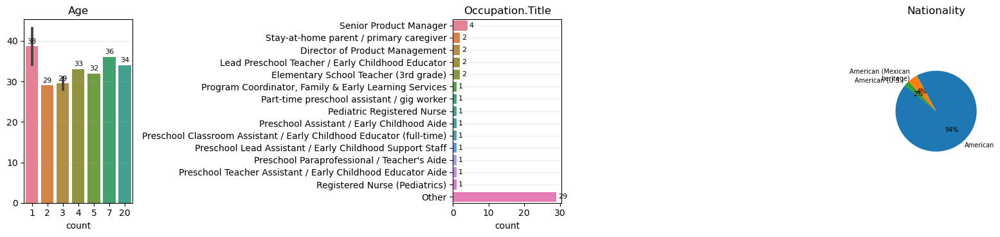

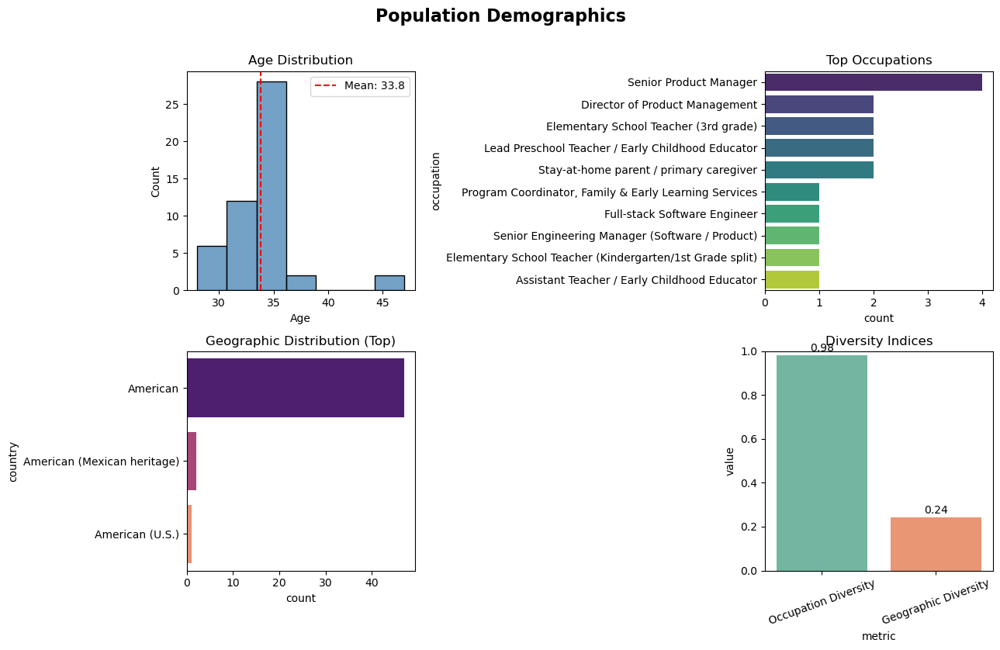

Persona composition keys found: ['interests', 'skills', 'beliefs', 'goals', 'likes_dislikes', 'routines', 'relationship_roles', 'communication_style', 'health', 'personality_traits']
[DEBUG persona_plot] facet 'interests' empty -> hidden
[DEBUG persona_plot] facet 'goals' empty -> hidden
[DEBUG persona_plot] facet 'likes_dislikes' empty -> hidden
[DEBUG persona_plot] facet 'relationship_roles' empty -> hidden
[DEBUG persona_plot] facet 'health' empty -> hidden


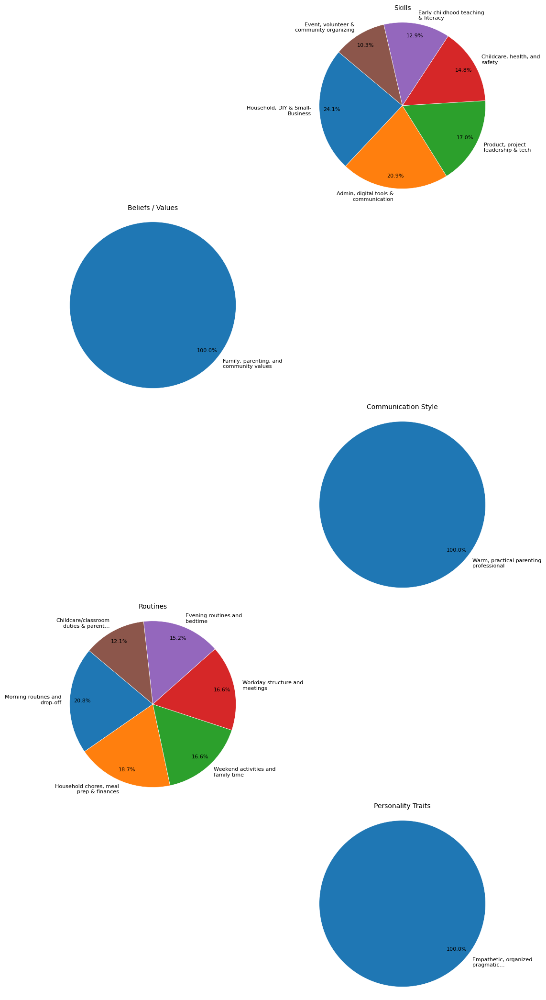

{'age': 28     3
 29     2
 30     1
 31     3
 32     5
 33     4
 34    20
 35     1
 36     7
 37     1
 38     1
 45     1
 47     1
 Name: count, dtype: int64,
 'occupation.title': Assistant Store Manager / Floor Supervisor                                                                       1
 Assistant Teacher / Early Childhood Educator                                                                     1
 Director of Product Management                                                                                   2
 Early Childhood Educator / Teacher Assistant                                                                     1
 Elementary School Teacher (1st-2nd grade)                                                                        1
 Elementary School Teacher (2nd Grade)                                                                            1
 Elementary School Teacher (2nd grade); part-time curriculum consultant for a local nonprofit literacy program    1
 El

In [13]:
profiler = Profiler()
profiler.profile(people)

Checkpoint the simulation state to disk, to avoid having to re-run the expensive agent sampling process, unless really necessary.

In [14]:
control.checkpoint()

2025-09-19 23:09:55,487 - tinytroupe - DEBUG - Checkpointing simulation state...
2025-09-19 23:09:55,488 - tinytroupe - DEBUG - No unsaved cache changes to save to file.


Now let's enclose the audience in an environment, to make it easier to interact with. Note that we set `broadcast_if_no_target` to `False`, which instructs the environment to **do not** broadcast what specific agents say to the others (unless the agent deliberately specify the target). We are not simulating a focus group, so we don't want discussions.


In [15]:
market = TinyWorld(f"Target audience ({target_nationality})", people, broadcast_if_no_target=False)

2025-09-19 23:09:55,524 - tinytroupe - DEBUG - Adding agent Jasmine Patrice Carter to the environment.
2025-09-19 23:09:55,526 - tinytroupe - DEBUG - Adding agent Ava Mei Lin to the environment.
2025-09-19 23:09:55,529 - tinytroupe - DEBUG - Adding agent Evan Thomas Harper to the environment.
2025-09-19 23:09:55,530 - tinytroupe - DEBUG - Adding agent Claire Elizabeth Martin to the environment.
2025-09-19 23:09:55,531 - tinytroupe - DEBUG - Adding agent Camila Elena Torres to the environment.
2025-09-19 23:09:55,533 - tinytroupe - DEBUG - Adding agent Caroline Elise Hart to the environment.
2025-09-19 23:09:55,536 - tinytroupe - DEBUG - Adding agent Caitlin Emerson Price to the environment.
2025-09-19 23:09:55,538 - tinytroupe - DEBUG - Adding agent Alejandra Maribel Hernandez to the environment.
2025-09-19 23:09:55,539 - tinytroupe - DEBUG - Adding agent Lucia Elena Martinez to the environment.
2025-09-19 23:09:55,542 - tinytroupe - DEBUG - Adding agent Olivia Kate Reynolds to the env

## Perform the research

Now we actually ask agents about their opinion. Note that we are asking for specific answers (Yes, No, Maybe), both to convey the granularity of preference we seek, and to make it easier to extract the results later. In general, a coarser granuarity is likely to have higher quality, since it requires less information to be computed accurately.

In [16]:
market.broadcast(interviewer_introduction)
market.broadcast(interviewer_main_question)
market.broadcast_thought(inner_monologue)

2025-09-19 23:09:55,620 - tinytroupe - DEBUG - -----------------------------------------> Transaction: broadcast with args ('\n   Artificial Intelligence (AI) can now create compelling stories for young children, tell them aloud and \n   even generate illustrations of the scenes, like a regular book. We are considering creating a "digital story-teller" to leverage \n   this, and would like the opinion of parents. The key idea is that that the child would be able to independently talk to the AI \n   story-teller and request specific stories, anything the child can imagine. Our main doubt is HOW to deliver this technology to \n   the children.\n   \n   Your task is to order the options based on your preferences. The first option is the one you like the most, and the last option \n   is the one you like the least. So, for example, if you respond with "B, A, C, D, E", it means you prefer option B the most and \n   option E the least.\n    ',) and kwargs {} under simulation None, parallel=F

USER --> Caitlin Emerson Price: [CONVERSATION] 
          >     Artificial Intelligence (AI) can now create compelling stories for young children,
          > tell them aloud and     even generate illustrations of the scenes, like a regular book.
          > We are considering creating a "digital story-teller" to leverage     this, and would
          > like the opinion of parents. The key idea is that that the child would be able to
          > independently talk to the AI     story-teller and request specific stories, anything the
          > child can imagine. Our main doubt is HOW to deliver this technology to     the children.
          > Your task is to order the options based on your preferences. The first option is the one
          > you like the most, and the last option     is the one you like the least. So, for
          > example, if you respond with "B, A, C, D, E", it means you prefer option B the most and
          > option E the least.

       + --> Camila Elena Torres

       + --> Heather Lynn Montgomery

       + --> ...others...

2025-09-19 23:09:55,870 - tinytroupe - DEBUG - Will attempt to checkpoint simulation state after transaction execution.
2025-09-19 23:09:55,873 - tinytroupe - DEBUG - -----------------------------------------> Transaction: broadcast with args (' \n    So the main question for you to rank the options is this: what kind of AI-enabled story-telling device would you buy for your very young children (3 to 5 y.o.)? \n    \n    Pick from the options below (A, B, C, D, E) and please explain your choices. Here are the details about each option:\n\n\n     - (A) DEDICATED SINGLE-PURPOSE DEVICE (AUDIO + IMAGES): A single-purpose portable device, where there are no apps or anything else. There is just a single button to turn it ON or OFF, plus a screen, and when ON the child can talk to an animated story-teller, ask stories and the device then tells the requested stories aloud, including related story illustrations too shown on a screen, all on demand. The child can interrupt it at any time too. Th

... (52 outputs left out)

Megan Elise Hartman --> Megan Elise Hartman: [THOUGHT] 
                         >      I will be honest as I understand they are not here to judge me, but
                         > just to learn from me.      Such choices depend on many factors, but I
                         > will make my best guess, considering my current      situation in life,
                         > location, job and interests.      Now I **must** first THINK deeply about
                         > the question, consider all the factors that might influence my decision,
                         > and only then I will TALK with my response to the question as best, as
                         > detailed and as honestly as I can.      I will respect the expected
                         > response format, giving first my ranked choices and then justifying that
                         > ranking. I MUST adhere to the format strictly,     saying "Ranking: ..."
                         > and "Justification: ...", otherwise my answer might be discarded. For the
                         > choices, I WILL USE LETTERS (A, B, C, D, E).

Mariana Alvarez --> Mariana Alvarez: [THOUGHT] 
                     >      I will be honest as I understand they are not here to judge me, but just
                     > to learn from me.      Such choices depend on many factors, but I will make
                     > my best guess, considering my current      situation in life, location, job
                     > and interests.      Now I **must** first THINK deeply about the question,
                     > consider all the factors that might influence my decision,     and only then
                     > I will TALK with my response to the question as best, as detailed and as
                     > honestly as I can.      I will respect the expected response format, giving
                     > first my ranked choices and then justifying that ranking. I MUST adhere to
                     > the format strictly,     saying "Ranking: ..." and "Justification: ...",
                     > otherwise my answer might be discarded. For the choices, I WILL USE LETTERS
                     > (A, B, C, D, E).

Sasha Nguyen --> Sasha Nguyen: [THOUGHT] 
                  >      I will be honest as I understand they are not here to judge me, but just to
                  > learn from me.      Such choices depend on many factors, but I will make my best
                  > guess, considering my current      situation in life, location, job and
                  > interests.      Now I **must** first THINK deeply about the question, consider
                  > all the factors that might influence my decision,     and only then I will TALK
                  > with my response to the question as best, as detailed and as honestly as I can.
                  > I will respect the expected response format, giving first my ranked choices and
                  > then justifying that ranking. I MUST adhere to the format strictly,     saying
                  > "Ranking: ..." and "Justification: ...", otherwise my answer might be discarded.
                  > For the choices, I WILL USE LETTERS (A, B, C, D, E).

2025-09-19 23:09:56,936 - tinytroupe - DEBUG - Will attempt to checkpoint simulation state after transaction execution.


In [17]:
market.run(1)

2025-09-19 23:09:56,966 - tinytroupe - DEBUG - -----------------------------------------> Transaction: run with args (1,) and kwargs {} under simulation default, parallel=False.
2025-09-19 23:09:56,967 - tinytroupe - DEBUG - >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>> Object TinyWorld(name='Target audience (American)') is already captured by simulation default.
2025-09-19 23:09:56,969 - tinytroupe - INFO - [Target audience (American)] Running world simulation step 1 of 1.


───────────────────────────────────── Target audience (American) step 1 of 1 ──────────────────────────────────────

2025-09-19 23:09:56,974 - tinytroupe - DEBUG - -----------------------------------------> Transaction: _step with args () and kwargs {'timedelta_per_step': None, 'randomize_agents_order': True, 'parallelize': True} under simulation default, parallel=False.
2025-09-19 23:09:56,976 - tinytroupe - DEBUG - >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>> Object TinyWorld(name='Target audience (American)') is already captured by simulation default.
2025-09-19 23:09:56,977 - tinytroupe - INFO - [Target audience (American)] No timedelta provided, so the datetime was not advanced.
2025-09-19 23:09:56,980 - tinytroupe - DEBUG - -----------------------------------------> Transaction: act with args () and kwargs {'return_actions': True} under simulation default, parallel=False.
2025-09-19 23:09:56,989 - tinytroupe - DEBUG - >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>> Object TinyPerson(name='Caitlin Emerson Price') is already captured by simulation default.
2025-09-19 23:09:56,991 - tinytroupe - DEBUG - --------------------

Camila Elena Torres acts: [THINK] 
                         > Okay, pienso en voz alta: los niños de 3-5 necesitan algo seguro, fácil,
                         > y que no dependa de que yo esté pegada al teléfono todo el tiempo. Me
                         > preocupo por el presupuesto—no puedo gastar mucho—y por la privacidad y
                         > anuncios molestos. También quiero que sea bilingüe o que permita
                         > historias en español, que pueda pausarse cuando hay que cambiar pañales o
                         > atender a otro niño, y que no tenga apps que los distraigan o que los
                         > dejen ver cosas no apropiadas. Prefiero algo robusto, con control
                         > parental sencillo y offline si es posible. Ahora voy a responder en el
                         > formato pedido: ranking primero y luego la justificación clara y breve
                         > para cada opción.

2025-09-19 23:09:57,746 - tinytroupe - WARNING - Agent Anika Meera Shah is already in the environment.
2025-09-19 23:09:57,797 - tinytroupe - WARNING - Agent Malia Kealoha-Begay is already in the environment.


Camila Elena Torres acts: [TALK] 
                         > Ranking: A, D, C, B, E  Justification: A — Dedicated single-purpose
                         > device: Me encanta esta opción para mis niños en la clase y para casa. Es
                         > simple (un botón), no tiene apps ni distracciones, se puede pausar fácil,
                         > y si trae imágenes estáticas es como un libro digital. Es más seguro para
                         > niños pequeños, menos dependiente del Wi‑Fi, y normalmente más barato que
                         > un tablet bueno. Además, como maestra de Early Childhood, valoro que el
                         > dispositivo no reemplace a la maestra pero apoye la lectura
                         > independiente. Por eso A es mi primera elección.  D — (Device/toy with
                         > curated content): Poneo a D en segundo porque si es un juguete pensado
                         > para niños, con contenido curado y controles parentales, puede ser muy
                         > amigable y resistente al uso en la sala. Si tiene voces y algunas
                         > interacciones preprogramadas, entretiene sin abrir la puerta a internet
                         > peligrosa. Lo ubico segundo porque depende de cómo lo implementen—si
                         > tiene menos opciones bilingües o es caro, baja en preferencia.  C —
                         > (Smart speaker/voice assistant): Lo pong (...)

... (290 outputs left out)

Sasha Nguyen acts: [TALK] 
                  > Ranking: A, D, B, C, E  Justification: A (Dedicated single-purpose device) — My
                  > top pick. It minimizes distractions, is predictable for a 3–5 y.o., can be
                  > designed with clear parental controls and limited data collection, and feels
                  > most in line with play-based, short interactive sessions I endorse. It also
                  > makes bilingual parental input easier (no app store to navigate) and is lower
                  > risk for privacy and overuse. D (Curated/parent-supervised option) — I rank this
                  > second because curated content with explicit parental controls and research-
                  > backed stories keeps quality high while still allowing some flexibility; it’s a
                  > good compromise if it enforces privacy and time limits. B (App-like but with
                  > parental controls) — Useful if it’s evidence-based, but still opens the door to
                  > more apps and potential distraction; I’d only choose this if privacy settings
                  > are strong and content is curated. C (Full-featured tablet/platform) — Lower on
                  > my list: offers most flexibility but also most risk of distraction, in-app
                  > purchases,  (...)

2025-09-19 23:12:32,581 - tinytroupe - DEBUG - [Sasha Nguyen] Current episode event count: 6.
2025-09-19 23:12:32,582 - tinytroupe - DEBUG - [Sasha Nguyen] Cognitive state: {'goals': 'Provide a clear, parent-centered ranking and justification of AI-enabled story-telling device options.', 'context': ['Responding to a prompt about what device I would buy for 3–5 y.o. children.', 'I prioritize child development best practices, bilingual exposure, privacy, and parental controls.'], 'attention': 'Balancing developmental appropriateness (short, interactive, play-based use), privacy/data minimization, parental oversight, and ease-of-use for busy families.', 'emotions': 'Focused and protective; pragmatic about trade-offs; slightly wary of data-hungry solutions.'}
2025-09-19 23:12:32,583 - tinytroupe - DEBUG - -----------------------------------------> Transaction: _update_cognitive_state with args () and kwargs {'goals': 'Provide a clear, parent-centered ranking and justification of AI-enabled

Sasha Nguyen acts: [DONE] 
                  > Finished response.

2025-09-19 23:12:33,121 - tinytroupe - DEBUG - Will attempt to checkpoint simulation state after transaction execution.
2025-09-19 23:12:33,123 - tinytroupe - DEBUG - -----------------------------------------> Transaction: pop_latest_actions with args () and kwargs {} under simulation default, parallel=False.
2025-09-19 23:12:33,125 - tinytroupe - DEBUG - >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>> Object TinyPerson(name='Caitlin Emerson Price') is already captured by simulation default.
2025-09-19 23:12:33,126 - tinytroupe - DEBUG - Will attempt to checkpoint simulation state after transaction execution.
2025-09-19 23:12:33,128 - tinytroupe - DEBUG - -----------------------------------------> Transaction: _handle_actions with args (TinyPerson(name='Caitlin Emerson Price'), [{'type': 'THINK', 'content': 'I need to be explicit about my rationale before I speak. Key criteria for a device I would buy for a 3–5 year old: 1) safety/privacy (no data collection or strong parental controls), 2) developme

In [18]:
control.checkpoint()

2025-09-19 23:12:34,635 - tinytroupe - DEBUG - Checkpointing simulation state...
2025-09-19 23:12:34,638 - tinytroupe - DEBUG - Now saving cache file to ai_enabled_children_story_telling.cache.json.


## Extract results and analyze

Now we can actually extract the results.

In [19]:
results = results_extractor.extract_results_from_agents(people)
for index, (person, result) in enumerate(zip(people, results)):
    if not isinstance(result, dict) or not isinstance(result.get("response"), str):
        print(f"Retrying invalid ranking extraction for {person.name} with a JSON-format reminder.")
        retry_hints = dict(results_extractor.default_fields_hints)
        retry_hints["response"] += " Return a valid JSON object with properly closed string values, including both response and justification."
        results[index] = results_extractor.extract_results_from_agents([person], fields_hints=retry_hints)[0]

2025-09-19 23:12:56,255 - tinytroupe - DEBUG - Using  API type openai.
2025-09-19 23:12:56,893 - tinytroupe - DEBUG - Token count: model not found. Using cl100k_base encoding.
2025-09-19 23:12:56,895 - tinytroupe - DEBUG - Token count: no info on GPT-5 tokenizer yet, so we are just reusing GPT-4's.
2025-09-19 23:12:56,900 - tinytroupe - DEBUG - Sending messages to OpenAI API. Token count=2369.
2025-09-19 23:12:56,902 - tinytroupe - DEBUG - Calling model with client class OpenAIClient.
2025-09-19 23:12:56,904 - tinytroupe - DEBUG - Calling LLM model with these parameters: {'model': 'gpt-5-mini', 'max_completion_tokens': 32000, 'frequency_penalty': 0.0, 'presence_penalty': 0.0, 'timeout': 480.0, 'stream': False, 'n': 1}. Not showing 'messages' parameter.
2025-09-19 23:13:10,594 - tinytroupe - DEBUG - Got response from API: ChatCompletion(id='chatcmpl-CHhNpynEjv7zIPGR4jvWNhaiLc2W9', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='{"name

Extraction raw result message: {'content': '{"name": "Jasmine Patrice Carter", "response": "A-D-B-C-E", "justification": " - A (Dedicated single-purpose device): My top pick. Child-proof, simple interface and nothing extra to distract a preschooler — that matters. If it tells stories with pictures and lets a child interrupt, it keeps the ritual of being read to but still lets little ones feel independent. For working parents and community programs, low fuss and no extra apps or in-app ads is a big win. Affordable pricing and portability would make it great for families and for lending through libraries or the center.   - D (Curated device with strong parental controls / curated updates): Second because it balances safety with the ability to refresh content. If parents or programs can add new books and control what the child sees, that helps literacy variety. It’s a bit more complex than A, so it needs clear instructions and good customer support, but I like the flexibility for classroo

2025-09-19 23:13:11,444 - tinytroupe - DEBUG - Token count: model not found. Using cl100k_base encoding.
2025-09-19 23:13:11,446 - tinytroupe - DEBUG - Token count: no info on GPT-5 tokenizer yet, so we are just reusing GPT-4's.
2025-09-19 23:13:11,457 - tinytroupe - DEBUG - Sending messages to OpenAI API. Token count=2395.
2025-09-19 23:13:11,460 - tinytroupe - DEBUG - Calling model with client class OpenAIClient.
2025-09-19 23:13:11,462 - tinytroupe - DEBUG - Calling LLM model with these parameters: {'model': 'gpt-5-mini', 'max_completion_tokens': 32000, 'frequency_penalty': 0.0, 'presence_penalty': 0.0, 'timeout': 480.0, 'stream': False, 'n': 1}. Not showing 'messages' parameter.
2025-09-19 23:13:25,499 - tinytroupe - DEBUG - Got response from API: ChatCompletion(id='chatcmpl-CHhO3nnF56UQHy8FEtJfbucKipdML', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='{"name":"Ava Mei Lin","response":"D-A-C-B-E","justification":"1) D — Parent‑s

Extraction raw result message: {'content': '{"name":"Ava Mei Lin","response":"D-A-C-B-E","justification":"1) D — Parent‑supervised/parent‑curated experience (my top pick).  For Luna I want something parents set up and can approve: curated stories, parental dashboard (usage, recommendations), explicit privacy controls, and an easy bedtime mode. It preserves the ritual (we can review or pick stories together), supports bilingual content deliberately, and avoids opaque always‑on data collection. It also lets me limit sessions and integrate the device into family routines — high trust and high control.  2) A — Dedicated single‑purpose device (audio + images).  I like the simplicity and the lack of other apps — fewer distractions and a more book‑like experience (static images + spoken text) which is gentle for bedtime. My concern is: does it phone home? If it truly stores content locally or has strong privacy guarantees and a clear parental setup, it’s very attractive. I rank it second beca

2025-09-19 23:13:26,081 - tinytroupe - DEBUG - Token count: model not found. Using cl100k_base encoding.
2025-09-19 23:13:26,083 - tinytroupe - DEBUG - Token count: no info on GPT-5 tokenizer yet, so we are just reusing GPT-4's.
2025-09-19 23:13:26,091 - tinytroupe - DEBUG - Sending messages to OpenAI API. Token count=2395.
2025-09-19 23:13:26,092 - tinytroupe - DEBUG - Calling model with client class OpenAIClient.
2025-09-19 23:13:26,093 - tinytroupe - DEBUG - Calling LLM model with these parameters: {'model': 'gpt-5-mini', 'max_completion_tokens': 32000, 'frequency_penalty': 0.0, 'presence_penalty': 0.0, 'timeout': 480.0, 'stream': False, 'n': 1}. Not showing 'messages' parameter.
2025-09-19 23:13:40,675 - tinytroupe - DEBUG - Got response from API: ChatCompletion(id='chatcmpl-CHhOIXrOen9aL3aRA3d2wrOKGasu2', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='{"name":"Evan Thomas Harper","response":"A-B-D-C-E","justification":"A (Dedic

Extraction raw result message: {'content': '{"name":"Evan Thomas Harper","response":"A-B-D-C-E","justification":"A (Dedicated single-purpose device) — My top pick. For a 3–5 year old I prioritize simplicity, low distraction, and privacy. A single-purpose storyteller that offers audio + static illustrations lets the child independently ask for stories without app stores, notifications, or tracking. It minimizes parental oversight friction and reduces data-sharing risks while still delivering a book-like experience that supports language and imagination.  B (Curated kid tablet / locked-down device) — Second. This is more flexible and can grow with the child (additional narratives, interactive features), and strong parental controls make it workable. I prefer it only if the vendor has transparent privacy policies and easy parental curation. The downside vs. A is greater complexity and a higher risk of distraction if controls fail or aren’t used consistently.  D (Audio-first smart speaker 

... (90 outputs left out)

2025-09-19 23:26:29,424 - tinytroupe - DEBUG - Token count: model not found. Using cl100k_base encoding.
2025-09-19 23:26:29,427 - tinytroupe - DEBUG - Token count: no info on GPT-5 tokenizer yet, so we are just reusing GPT-4's.
2025-09-19 23:26:29,434 - tinytroupe - DEBUG - Sending messages to OpenAI API. Token count=2310.
2025-09-19 23:26:29,435 - tinytroupe - DEBUG - Calling model with client class OpenAIClient.
2025-09-19 23:26:29,436 - tinytroupe - DEBUG - Calling LLM model with these parameters: {'model': 'gpt-5-mini', 'max_completion_tokens': 32000, 'frequency_penalty': 0.0, 'presence_penalty': 0.0, 'timeout': 480.0, 'stream': False, 'n': 1}. Not showing 'messages' parameter.
2025-09-19 23:26:40,392 - tinytroupe - DEBUG - Got response from API: ChatCompletion(id='chatcmpl-CHhav9VjQkvqFgjAfj0htjVWxkw9C', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='{"name": "Mariana Alvarez", "response": "A-B-D-C-E", "justification": "A — De

Extraction raw result message: {'content': '{"name": "Mariana Alvarez", "response": "A-B-D-C-E", "justification": "A — Dedicated single-purpose device (best): Me gusta mucho esta opción. For our preschoolers this is ideal: simple, like a storybook that talks back. No extra apps to distract or hidden content, so safe for little manos. It can be left for independent play without parents worrying about accidental purchases or internet exposure. Durability and a reasonable price make it realistic for families and classrooms. Bilingual story options and the ability to interrupt are perfect for circle time or nap transitions.  B — Controlled tablet/app with strong parental controls (second): This is useful if it can run offline and parents/teachers can lock it to the storyteller app only. It offers flexibility (more stories, updates) and can be bilingual, but I worry about distractions, accidental exits, and screen fragility. Good if families already have a tablet and the app is inexpensive 

2025-09-19 23:26:41,006 - tinytroupe - DEBUG - Token count: model not found. Using cl100k_base encoding.
2025-09-19 23:26:41,008 - tinytroupe - DEBUG - Token count: no info on GPT-5 tokenizer yet, so we are just reusing GPT-4's.
2025-09-19 23:26:41,014 - tinytroupe - DEBUG - Sending messages to OpenAI API. Token count=2361.
2025-09-19 23:26:41,016 - tinytroupe - DEBUG - Calling model with client class OpenAIClient.
2025-09-19 23:26:41,018 - tinytroupe - DEBUG - Calling LLM model with these parameters: {'model': 'gpt-5-mini', 'max_completion_tokens': 32000, 'frequency_penalty': 0.0, 'presence_penalty': 0.0, 'timeout': 480.0, 'stream': False, 'n': 1}. Not showing 'messages' parameter.
2025-09-19 23:26:56,727 - tinytroupe - DEBUG - Got response from API: ChatCompletion(id='chatcmpl-CHhb7QA7FCZoaAX1UtPye1PY5A9M8', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='{"name":"Sasha Nguyen","response":"A-D-B-C-E","justification":"A (Dedicated s

Extraction raw result message: {'content': '{"name":"Sasha Nguyen","response":"A-D-B-C-E","justification":"A (Dedicated single-purpose device) — My top pick. It minimizes distractions, is predictable for a 3–5 y.o., can be designed with clear parental controls and limited data collection, and feels most in line with play-based, short interactive sessions I endorse. It also makes bilingual parental input easier (no app store to navigate) and is lower risk for privacy and overuse. D (Curated/parent-supervised option) — I rank this second because curated content with explicit parental controls and research-backed stories keeps quality high while still allowing some flexibility; it’s a good compromise if it enforces privacy and time limits. B (App-like but with parental controls) — Useful if it’s evidence-based, but still opens the door to more apps and potential distraction; I’d only choose this if privacy settings are strong and content is curated. C (Full-featured tablet/platform) — Low

In [20]:
# make sure the results are all dicts
filtered_results = [item for item in results if isinstance(item, dict)]

In [21]:
# load a list of dicts into a pandas dataframe
df = pd.DataFrame(filtered_results)

df["response"] = df["response"].str.replace("OPTION_", "", regex=False)
valid_rankings = df["response"].map(
    lambda response: isinstance(response, str) and (
        response == "N/A" or (
            len(response.split("-")) == 5 and set(response.split("-")) == set("ABCDE")
        )
    )
)
if len(df) != population_size or not valid_rankings.all():
    invalid_results = df.loc[~valid_rankings].to_dict("records")
    raise ValueError(
        f"Expected one complete A-E ranking or explicit N/A per sampled person ({population_size} rows); "
        f"got {len(df)} rows; invalid results: {invalid_results}"
    )

df

,name,response,justification
0,Jasmine Patrice Carter,A-D-B-C-E,- A (Dedicated single-purpose device): My top...
1,Ava Mei Lin,D-A-C-B-E,1) D — Parent‑supervised/parent‑curated experi...
2,Evan Thomas Harper,A-B-D-C-E,A (Dedicated single-purpose device) — My top p...
3,Claire Elizabeth Martin,A-B-C-D-E,A — Dedicated single-purpose device (best): As...
4,Camila Elena Torres,A-D-C-B-E,A — Dedicated single-purpose device: Me encant...
5,Caroline Elise Hart,A-C-B-D-E,A (Dedicated single-purpose device): Top choic...
6,Caitlin Emerson Price,A-C-B-D-E,"A — Top choice. A dedicated, single-purpose st..."
7,Alejandra Maribel Hernandez,A-C-D-E-B,A — Me gusta más porque es un dispositivo sing...
8,Lucia Elena Martinez,A-C-E-B-D,A — Dedicated single-purpose device is my top ...
9,Olivia Kate Reynolds,A-B-C-D-E,A — Top choice. A dedicated single-purpose sto...


In [22]:
df["response"].value_counts()

response
A-C-B-D-E    21
A-B-C-D-E     6
A-D-B-C-E     5
A-B-D-C-E     4
A-D-C-B-E     3
A-C-E-B-D     2
A-C-D-B-E     2
D-A-C-B-E     1
A-C-D-E-B     1
B-A-C-D-E     1
A-C-B-E-D     1
A-D-E-B-C     1
A-C-E-D-B     1
C-A-D-B-E     1
Name: count, dtype: int64

We can also chat with the agents in an ad-hoc way, to get a more detailed understanding if needed.

In [23]:
from tinytroupe.ui import AgentChatJupyterWidget

# Create and display the enhanced chat widget
chat_interface = AgentChatJupyterWidget(people)
chat_interface.display()

In [24]:
control.end()

2025-09-19 23:26:56,995 - tinytroupe - DEBUG - Ending simulation.
2025-09-19 23:26:56,997 - tinytroupe - DEBUG - Checkpointing simulation state...
2025-09-19 23:26:56,998 - tinytroupe - DEBUG - No unsaved cache changes to save to file.


## Empirical Data Validation
Now let's see how the above matches the same research done with actual real people!

In [25]:
control_data = SimulationExperimentEmpiricalValidator.read_empirical_data_from_csv(
            file_path="../data/empirical/07.17.2025 - Market Research - AI-enabled story telling device or app - Raw Data.csv",
            experimental_data_type="ordinal_ranking_per_agent",
            agent_id_column="Responder #",
            value_column="Vote",
            agent_comments_column="Explanation",
            agent_attributes_columns=["Age Range", "Gender Identity", "Political Affiliation", "Racial Or Ethnic Identity"],
            dataset_name="AI-enabled Story Telling Real Survey"
        )

In [26]:
control_data

SimulationExperimentDataset(name='AI-enabled Story Telling Real Survey', description='Empirical data loaded from 07.17.2025 - Market Research - AI-enabled story telling device or app - Raw Data.csv', key_results={'A_rank': [4, 1, 3, 3, 3, 1, 2, 1, 3, 4, 1, 3, 1, 5, 5, 4, 5, 2, 1, 3, 2, 4, 4, 4, 1, 1, 4, 1, 1, 4, 2, 2, 3, 4, 1, 5, 5, 4, 3, 3, 3, 1, 1, 4, 2, 1, 1, 3, 2, 1], 'B_rank': [1, 5, 2, 1, 5, 5, 4, 5, 5, 1, 5, 1, 5, 4, 2, 2, 3, 1, 3, 1, 4, 1, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 3, 4, 4, 5, 5, 5, 5, 5, 5, 3, 5, 5, 5, 5, 5, 3], 'C_rank': [2, 3, 4, 4, 1, 3, 3, 4, 2, 2, 2, 4, 3, 3, 1, 5, 2, 4, 4, 5, 5, 2, 1, 2, 3, 2, 1, 4, 2, 1, 3, 1, 1, 1, 2, 2, 3, 1, 1, 1, 2, 2, 2, 5, 3, 4, 2, 4, 1, 2], 'D_rank': [3, 2, 1, 5, 4, 2, 1, 3, 4, 5, 3, 2, 4, 1, 3, 1, 4, 5, 2, 2, 3, 3, 3, 1, 2, 3, 2, 2, 4, 3, 1, 4, 4, 2, 4, 3, 1, 2, 4, 4, 4, 4, 4, 1, 1, 3, 4, 2, 4, 4], 'E_rank': [5, 4, 5, 2, 2, 4, 5, 2, 1, 3, 4, 5, 2, 2, 4, 3, 1, 3, 5, 4, 1, 5, 2, 3, 4, 4, 3, 3, 3, 2, 4, 3, 2, 3, 5, 1, 2, 3, 2, 2, 1, 3, 3,

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rank_cols = [k for k in control_data.key_results.keys() if k.endswith("_rank")]
option_names = [c.replace("_rank", "") for c in rank_cols]

df_control = pd.DataFrame({opt: control_data.key_results[f"{opt}_rank"] for opt in option_names})
# Attach demographics (optional)
for attr, values in control_data.agent_attributes.items():
    df_control[attr] = values

df_control.head()

,A,B,C,D,E,Age Range,Gender Identity
0,4,1,2,3,5,25-34,Female
1,1,5,3,2,4,25-34,Male
2,3,2,4,1,5,35-44,Male
3,3,1,4,5,2,35-44,Male
4,3,5,1,4,2,35-44,Male


(0.0, 1.0)

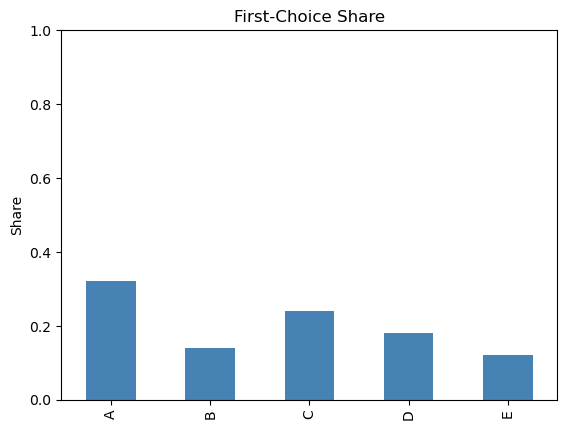

In [28]:
first_choice = (df_control == 1).sum()
(first_choice / len(df_control)).loc[option_names].plot(kind="bar", color="steelblue")
plt.ylabel("Share")
plt.title("First-Choice Share")
plt.ylim(0, 1)

In [29]:

# Create treatment data with matching column name and data type
treatment_data = SimulationExperimentEmpiricalValidator.read_empirical_data_from_dataframe(
    df=df,
    experimental_data_type="ordinal_ranking_per_agent",
    agent_id_column="name",
    value_column="Vote",
    agent_comments_column="justification",
    dataset_name="AI-enabled Story Telling Survey Simulation Results"
)

In [30]:
treatment_data

SimulationExperimentDataset(name='AI-enabled Story Telling Survey Simulation Results', description='Empirical data loaded from pandas DataFrame', key_results={'A_rank': [1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1], 'B_rank': [3, 4, 2, 2, 4, 3, 3, 5, 4, 2, 3, 4, 3, 3, 2, 4, 3, 2, 3, 3, 3, 1, 4, 3, 3, 2, 4, 3, 3, 4, 4, 3, 2, 3, 3, 3, 3, 3, 5, 2, 3, 3, 4, 3, 2, 3, 3, 3, 2, 3], 'C_rank': [4, 3, 4, 3, 3, 2, 2, 2, 2, 3, 2, 2, 2, 2, 3, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 4, 3, 2, 4, 5, 3, 2, 4, 2, 2, 2, 2, 4, 2, 3, 2, 2, 1, 2, 3, 2, 2, 4, 4, 4], 'D_rank': [2, 1, 3, 4, 2, 4, 4, 3, 5, 4, 4, 3, 4, 4, 4, 3, 4, 4, 4, 4, 4, 4, 5, 5, 4, 3, 2, 4, 2, 2, 2, 4, 3, 4, 4, 4, 4, 2, 4, 4, 4, 4, 3, 4, 4, 4, 4, 2, 3, 2], 'E_rank': [5, 5, 5, 5, 5, 5, 5, 4, 3, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 3, 4, 5, 5, 5, 5, 5, 3, 5, 5, 5, 5, 5, 5, 5, 5, 3, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5]}, result_types={'A_rank': 'per_a

In [31]:
result_ttest = validate_simulation_experiment_empirically(
        control_data=control_data,
        treatment_data=treatment_data,
        validation_types=["statistical"],
        output_format="values"
    )

In [32]:
result_ttest.overall_score

0.5882229273532587

In [33]:
result_ttest.statistical_results

{'common_metrics': ['C_rank', 'D_rank', 'A_rank', 'E_rank', 'B_rank'],
 'test_results': {'treatment': {'C_rank': {'test_type': 'Welch t-test (unequal variance)',
    'control_mean': 2.54,
    'treatment_mean': 2.62,
    'mean_difference': 0.08000000000000007,
    'percent_change': 3.1496062992126013,
    't_statistic': -0.3673414747018703,
    'p_value': 0.7142531330541259,
    'confidence_interval': (-0.3528410450044054, 0.5128410450044055),
    'confidence_level': 0.95,
    'significant': False,
    'degrees_of_freedom': 87.3191757271271,
    'control_sample_size': 50,
    'treatment_sample_size': 50,
    'control_std': 1.265072394476026,
    'treatment_std': 0.8780776777502463,
    'effect_size': 0.07346829494037407},
   'D_rank': {'test_type': 'Welch t-test (unequal variance)',
    'control_mean': 2.86,
    'treatment_mean': 3.48,
    'mean_difference': 0.6200000000000001,
    'percent_change': 21.678321678321684,
    't_statistic': -2.8432285342290164,
    'p_value': 0.00551015430

In [34]:
result_ttest.semantic_results

In [35]:
result_ks = validate_simulation_experiment_empirically(
        control_data=control_data,
        treatment_data=treatment_data,
        validation_types=["statistical"],
        statistical_test_type="ks_test",
        output_format="values"
    )

In [36]:
result_ks.overall_score

0.6906055730556938

In [37]:
result_ks.statistical_results

{'common_metrics': ['C_rank', 'D_rank', 'A_rank', 'E_rank', 'B_rank'],
 'test_results': {'treatment': {'C_rank': {'test_type': 'Kolmogorov-Smirnov test',
    'control_mean': 2.54,
    'treatment_mean': 2.62,
    'control_median': 2.0,
    'treatment_median': 2.0,
    'control_std': 1.265072394476026,
    'treatment_std': 0.8780776777502463,
    'ks_statistic': 0.22,
    'p_value': 0.17858668181221732,
    'significant': False,
    'control_sample_size': 50,
    'treatment_sample_size': 50,
    'effect_size': 0.22,
    'overlap_coefficient': 0.5625,
    'percentile_differences': {'p25_diff': 0.0,
     'p50_diff': 0.0,
     'p75_diff': -0.75,
     'p90_diff': 0.0,
     'p95_diff': -1.0},
    'interpretation': 'No significant difference between distributions',
    'confidence_level': 0.95},
   'D_rank': {'test_type': 'Kolmogorov-Smirnov test',
    'control_mean': 2.86,
    'treatment_mean': 3.48,
    'control_median': 3.0,
    'treatment_median': 4.0,
    'control_std': 1.2290696664135679

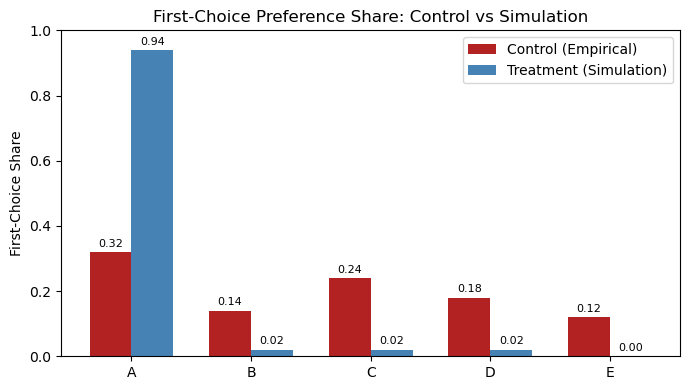

,Option,Control_FirstChoice,Treatment_FirstChoice
0,A,0.32,0.94
1,B,0.14,0.02
2,C,0.24,0.02
3,D,0.18,0.02
4,E,0.12,0.00


In [38]:
# Compare first-choice (rank==1) shares between control (empirical) and treatment (simulation)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def dataset_to_rank_df(dataset):
    rank_cols = [k for k in dataset.key_results if k.endswith("_rank")]
    opts = [c.replace("_rank", "") for c in rank_cols]
    if not rank_cols:
        raise ValueError("Dataset has no *_rank columns to compute first choices.")
    return pd.DataFrame({opt: dataset.key_results[f"{opt}_rank"] for opt in opts}), opts

# Build rank DataFrames
control_rank_df, options_control = dataset_to_rank_df(control_data)
try:
    treatment_rank_df, options_treatment = dataset_to_rank_df(treatment_data)
except Exception as e:
    # Fallback: attempt to reconstruct from original df if simulation dataset lacks expanded ranks
    if 'df' in globals():
        # Expect a column with combined ranking like "A,B,C,D,E" or single numeric; skip if not matching
        raise e
    else:
        raise e

# Ensure same option ordering
options = [opt for opt in options_control if opt in options_treatment]

# Compute first-choice shares (rank == 1)
fc_control = (control_rank_df[options] == 1).sum() / len(control_rank_df)
fc_treatment = (treatment_rank_df[options] == 1).sum() / len(treatment_rank_df)

comparison = pd.DataFrame({
    'Option': options,
    'Control_FirstChoice': [fc_control[o] for o in options],
    'Treatment_FirstChoice': [fc_treatment[o] for o in options]
})

# Plot side-by-side bars
x = np.arange(len(options))
width = 0.35
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(x - width/2, comparison['Control_FirstChoice'], width, label='Control (Empirical)', color='firebrick')
ax.bar(x + width/2, comparison['Treatment_FirstChoice'], width, label='Treatment (Simulation)', color='steelblue')
ax.set_xticks(x)
ax.set_xticklabels(options)
ax.set_ylabel('First-Choice Share')
ax.set_ylim(0, 1)
ax.set_title('First-Choice Preference Share: Control vs Simulation')

for i, val in enumerate(comparison['Control_FirstChoice']):
    ax.text(x[i] - width/2, val + 0.01, f"{val:.2f}", ha='center', va='bottom', fontsize=8)
for i, val in enumerate(comparison['Treatment_FirstChoice']):
    ax.text(x[i] + width/2, val + 0.01, f"{val:.2f}", ha='center', va='bottom', fontsize=8)

ax.legend()
plt.tight_layout()
plt.show()

comparison

## Borda Count Comparison
This section computes Borda scores (higher is better) for each option in the empirical control data vs the simulation treatment data. Rank 1 gets the maximum points (N-1), rank N gets 0. We also show normalized scores (0-1) and the difference.

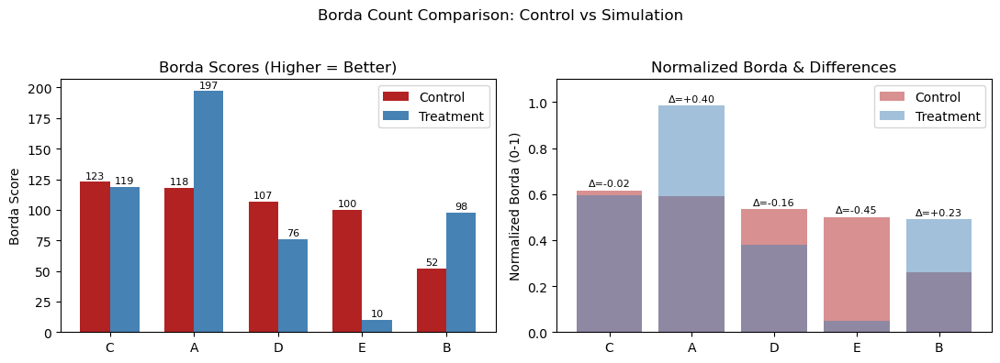

,Option,Control_Borda,Treatment_Borda,Control_Borda_Norm,Treatment_Borda_Norm,Norm_Diff
2,C,123,119,0.615,0.595,-0.020
0,A,118,197,0.590,0.985,0.395
3,D,107,76,0.535,0.380,-0.155
4,E,100,10,0.500,0.050,-0.450
1,B,52,98,0.260,0.490,0.230


In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reuse existing rank DataFrames: control_rank_df, treatment_rank_df, and options list
# Points scheme: with K options, rank 1 -> K-1 points, rank K -> 0 points
K = len(options)
points = {r: (K - r) for r in range(1, K+1)}

borda_control = control_rank_df[options].replace(points).sum()
borda_treatment = treatment_rank_df[options].replace(points).sum()

# Normalize (divide by max possible = (K-1) * number_of_respondents)
max_points_control = (K-1) * len(control_rank_df)
max_points_treatment = (K-1) * len(treatment_rank_df)

borda_control_norm = borda_control / max_points_control
borda_treatment_norm = borda_treatment / max_points_treatment

borda_df = pd.DataFrame({
    'Option': options,
    'Control_Borda': borda_control.values,
    'Treatment_Borda': borda_treatment.values,
    'Control_Borda_Norm': borda_control_norm.values,
    'Treatment_Borda_Norm': borda_treatment_norm.values,
})

borda_df['Norm_Diff'] = borda_df['Treatment_Borda_Norm'] - borda_df['Control_Borda_Norm']

# Order by control Borda descending for consistency
borda_df = borda_df.sort_values('Control_Borda', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11,4))
# Absolute Borda scores
x = np.arange(len(borda_df))
width = 0.35
axes[0].bar(x - width/2, borda_df['Control_Borda'], width, label='Control', color='firebrick')
axes[0].bar(x + width/2, borda_df['Treatment_Borda'], width, label='Treatment', color='steelblue')
axes[0].set_xticks(x)
axes[0].set_xticklabels(borda_df['Option'])
axes[0].set_ylabel('Borda Score')
axes[0].set_title('Borda Scores (Higher = Better)')
axes[0].legend()
for i, v in enumerate(borda_df['Control_Borda']):
    axes[0].text(i - width/2, v + max(borda_df['Control_Borda'])*0.01, f"{int(v)}", ha='center', va='bottom', fontsize=8)
for i, v in enumerate(borda_df['Treatment_Borda']):
    axes[0].text(i + width/2, v + max(borda_df['Control_Borda'])*0.01, f"{int(v)}", ha='center', va='bottom', fontsize=8)

# Normalized difference plot
axes[1].bar(borda_df['Option'], borda_df['Control_Borda_Norm'], alpha=0.5, label='Control', color='firebrick')
axes[1].bar(borda_df['Option'], borda_df['Treatment_Borda_Norm'], alpha=0.5, label='Treatment', color='steelblue')
for i, opt in enumerate(borda_df['Option']):
    c_val = borda_df.iloc[i]['Control_Borda_Norm']
    t_val = borda_df.iloc[i]['Treatment_Borda_Norm']
    axes[1].text(i, max(c_val, t_val) + 0.01, f"Δ={t_val - c_val:+.02f}", ha='center', va='bottom', fontsize=8)
axes[1].set_ylim(0, 1.1)
axes[1].set_ylabel('Normalized Borda (0-1)')
axes[1].set_title('Normalized Borda & Differences')
axes[1].legend()

plt.suptitle('Borda Count Comparison: Control vs Simulation')
plt.tight_layout(rect=[0,0,1,0.95])
plt.show()

borda_df